# Actividad 2 · Modelo de referencia y evaluación confiable

En esta actividad vamos a comparar dos formas de clasificar solicitudes de soporte. Al final elegirás una, explicarás por qué la elegiste y comprobarás que puedes guardar el modelo y volver a usarlo.

- **Valor:** 8% de la materia.
- **Asignación:** Lunes 5 de octubre de 2026.
- **Entrega:** Domingo 11 de octubre de 2026, a las 23:59, hora de Monterrey.

## ¿Qué vamos a resolver?

Imagina que un servicio de soporte recibe mensajes en español y necesita enviarlos al área adecuada: **acceso, pagos, conectividad o software**. Tu modelo sugerirá una de esas categorías. No hará cambios en cuentas ni realizará cobros.

Usaremos dos modelos que vimos en Clase 4: **regresión logística** y **Multinomial Naive Bayes**. Ambos aprenderán de los mismos ejemplos. La idea es hacer una comparación justa y dejar claro cómo llegaste a tu recomendación.

## ¿Qué puedes consultar?

Esta actividad se resuelve con lo trabajado en **Clases 1–4**. Puedes abrir sus notebooks, revisar los ejemplos y adaptarlos. No necesitas memorizar las funciones ni usar temas de Clases 5–6.

De las primeras clases retomamos el **corpus**, es decir, nuestra colección de textos, y las **etiquetas**, que indican la categoría de cada ejemplo. De Clase 3 usaremos **TF-IDF**, una forma de representar cada texto con números a partir de sus términos. De Clase 4 retomamos los clasificadores, su evaluación y la forma de guardarlos con `skops`.

Un **Pipeline** reúne la transformación del texto y el clasificador en un mismo objeto. Así, al recibir un mensaje nuevo, aplica los mismos pasos que aprendió durante el entrenamiento.

## Elige los datos y prepara la comparación

La opción que ya viene preparada es `data/corpus_actividad_02_v2.csv`. Son ejemplos ficticios diferentes de los usados en las demostraciones de clase. Conserva el reparto que trae el archivo y usa **solo `text_processed` como texto de entrada**.

También puedes usar el corpus de tu Actividad 1. En ese caso, explica de dónde viene, cómo lo preparaste y cómo separaste los datos. Debe tener al menos dos categorías en entrenamiento, y debes justificar que hay ejemplos suficientes y adecuados de tus categorías en validación y prueba. Ajusta la carga y `LABELS`, la lista de categorías, a tu propio corpus. No necesitas que tenga el mismo número de filas ni las mismas categorías que el corpus proporcionado. Si no puedes comprobar estas condiciones a tiempo, usa el archivo de esta actividad.

Antes de entrenar, deja por escrito:

1. Las dos alternativas: **TF-IDF + regresión logística** y **TF-IDF + Multinomial Naive Bayes**.

> Alternativa A: TF-IDF + Regresión Logística.
> Alternativa B: TF-IDF + Multinomial Naive Bayes.

2. La configuración de cada una. Puedes conservar los valores de Clase 4; no se pide probar muchas combinaciones de parámetros.

> **Vectorizador (idéntico para ambas):** `TfidfVectorizer(ngram_range=(1,1), lowercase=True, strip_accents=None, stop_words=None)`.
>
> **Alternativa A:** el vectorizador anterior + `LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=42)`.
>
> **Alternativa B:** el vectorizador anterior + `MultinomialNB(alpha=1.0)`.
>
> Cada alternativa se construye con un vectorizador y un clasificador (función `construir`), y ambas se entrenan solo con `train`.

3. La métrica principal con la que vas a comparar y la regla que usarás si hay empate.

> La comparación se hace sobre `validation` usando f1_macro (ya que, trata igual a todas las clases, por lo que es útil ante posible desbalance).
>
> Regla de desempate: 1) mayor f1_macro; 2) si empatan, mayor recall_macro; 3) si siguen empatando, menor tiempo de entrenamiento; 4) si aún empatan, gana Regresión Logística por ser más interpretable y estable en textos cortos.
>
> `test` se reserva para evaluar al modelo ya elegido.


Trabajaremos con tres **particiones**, es decir, tres grupos de datos con funciones distintas:

- **`train` — entrenamiento:** ejemplos de los que aprende el modelo.
- **`validation` — validación:** ejemplos que usamos para comparar las alternativas y elegir una.
- **`test` — prueba:** ejemplos que reservamos para evaluar el modelo después de elegirlo.

Los dos modelos deben usar exactamente los mismos datos en cada etapa. No uses `test` para decidir cuál gana. Una pequeña ventaja en este corpus no demuestra que un modelo sea mejor en cualquier situación.

## Antes de empezar

Usaremos Python con NumPy, pandas, scikit-learn, matplotlib y skops. NumPy ayuda con los cálculos; pandas organiza los datos en tablas; scikit-learn transforma textos, entrena y evalúa; matplotlib dibuja la matriz de confusión; skops guarda y recupera el modelo completo. No necesitas GPU ni descargar modelos ya entrenados.

### Colab

1. Abre este notebook y sube `corpus_actividad_02_v2.csv` al panel **Archivos**. Espera a que termine la carga.
2. Sube también `verificar_recarga.py`: lo usaremos en el paso 6.
3. Ejecuta las celdas de arriba hacia abajo. La primera celda de código instala únicamente las bibliotecas que faltan y muestra las versiones disponibles.
4. Si se instaló una biblioteca y después falla su importación, reinicia la sesión y vuelve a ejecutar desde el principio.

Al terminar, descarga el notebook y los archivos de `entrega/`. Guardar el notebook en Drive no guarda automáticamente los CSV ni el modelo que generaste durante la sesión.

In [18]:
from pathlib import Path
import sys, subprocess, importlib.util, json, platform, hashlib, re, unicodedata
from importlib.metadata import version
necesarios = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
              "sklearn":"scikit-learn==1.6.1", "skops":"skops==0.11.0",
              "matplotlib":"matplotlib==3.10.3"}
faltan = [paquete for modulo,paquete in necesarios.items()
          if importlib.util.find_spec(modulo) is None]
if faltan:
    subprocess.run([sys.executable,"-m","pip","install",*faltan],check=True)
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
import skops.io as sio
import matplotlib.pyplot as plt
versiones = {p:version(p) for p in necesarios.values() for p in [p.split("==")[0]]}
versiones["python"] = platform.python_version()
print(versiones)
completados = set()

{'numpy': '2.5.3', 'pandas': '3.0.5', 'scikit-learn': '1.9.0', 'skops': '0.11.0', 'matplotlib': '3.11.1', 'python': '3.12.10'}


## Conoce el archivo de datos

Antes de entrenar, revisemos qué significa cada columna. También puedes consultar `data/README.md`.

| Columna | Qué significa |
|---|---|
| `id` | Identificador de una fila; permite volver al ejemplo que quieres revisar. |
| `family` | Grupo de mensajes que son variantes de una misma solicitud. |
| `split` | Indica si la fila pertenece a `train`, `validation` o `test`. |
| `label` | Categoría de referencia con la que compararemos la predicción. |
| `text_original` | Texto antes de la preparación. |
| `text_processed` | Texto preparado que recibirá el modelo. |

Por ejemplo, dos maneras de escribir la misma solicitud pueden pertenecer a una misma familia. Deben quedarse en el mismo grupo de datos para evitar que el modelo se evalúe con una variante de algo que ya vio al entrenar.

`text_processed` conserva acentos y negaciones. Se aplicó **normalización NFC**, que unifica formas de representar caracteres como las letras acentuadas, y se redujeron los espacios sobrantes. Esto prepara el texto, pero no garantiza que el clasificador entienda una negación.

En el corpus proporcionado hay **40 familias, tres variantes por familia y cuatro categorías**. Por cada categoría, seis familias se usan para entrenamiento, dos para validación y dos para prueba. Los mensajes son ficticios, no contienen datos de personas reales y están autorizados para uso educativo.

Las categorías son: **acceso**, para problemas de cuenta o autenticación; **pagos**, para cargos y documentos de pago; **conectividad**, para red e internet; y **software**, para aplicaciones y archivos. Si un mensaje menciona un problema ya resuelto y otro que continúa, la etiqueta corresponde al que sigue pendiente.

El modelo recibe únicamente `text_processed`. No agregues `id`, `family`, `split` ni `label` al texto: son datos para organizar y evaluar el experimento. Conserva las familias y particiones originales. No muevas ejemplos entre grupos para mejorar la puntuación.

Este corpus ya está preparado para que te concentres en la comparación de modelos. Sus ejemplos cortos y repetitivos no cubren toda la variedad del lenguaje real. Si usas tu corpus de Actividad 1, conserva y explica tus propias decisiones de preparación.

La siguiente celda busca el CSV, lo carga en la tabla `df` y crea la carpeta `entrega/`, donde guardarás tus resultados. Si no encuentra el archivo, revisa que hayas terminado de subirlo a Colab o que hayas extraído la carpeta `data/` junto al notebook.

In [19]:
nombre = "corpus_actividad_02_v2.csv"
bases = [Path.cwd(), *Path.cwd().parents]
candidatos = [Path.cwd()/nombre]
for base in bases:
    candidatos += [base/"data"/nombre, base/"data"/nombre,
                   base/"data"/nombre]
ARCHIVO = next((p for p in candidatos if p.is_file()),None)
if ARCHIVO is None:
    raise FileNotFoundError("Extrae data/ junto al notebook o termina de subir el CSV al panel Archivos de Colab.")
df = pd.read_csv(ARCHIVO,keep_default_na=False,encoding="utf-8")
OUT = Path.cwd()/"entrega"
OUT.mkdir(exist_ok=True)
print("Fuente localizada:",ARCHIVO.name)

Fuente localizada: corpus_actividad_02_v2.csv


## 1. Revisa los datos antes de entrenar

Primero explica qué texto va a recibir tu modelo, qué categoría devolverá y para qué servirá esa respuesta. Después revisa la tabla:

1. Comprueba las columnas, los valores que faltan, los identificadores y cuántos ejemplos hay de cada categoría.
2. Revisa que cada familia aparezca en una sola partición. Haz lo mismo con los textos procesados que sean idénticos.
3. Comprueba que todas las categorías presentes en validación y prueba también estén en entrenamiento.
4. Anota el tamaño de cada grupo y explica si su distribución permite hacer la comparación. Conserva la tabla con `id`, `family`, `split` y `label`.

Estos controles ayudan a evitar una **fuga de información**: que el entrenamiento o la elección del modelo aprovechen datos que deberían estar reservados para otra etapa. Por ejemplo, repartir variantes de una misma solicitud entre entrenamiento y prueba puede hacer que el resultado parezca mejor de lo que realmente es.

No cambies las particiones después de ver los resultados. Recuerda que el texto de entrada es solo `text_processed`.

**Apoyo:** Clase 4, sección 1, función `comprobar_particiones`.

In [20]:
# Función de comprobación de particiones
def comprobar_particiones(tabla):
    obligatorias = {"id","family","split","label"}
    assert obligatorias <= set(tabla.columns), "Faltan columnas del contrato"
    assert tabla.id.is_unique, "IDs repetidos"
    assert not tabla[list(obligatorias)].isna().any().any(), "Hay ausencias"
    for col in obligatorias:
        assert tabla[col].astype(str).str.strip().ne("").all(), "Campo vacío: "+col
    assert set(tabla.split)=={"train","validation","test"}, "Revisar particiones"
    for col in ["family","text_processed"]:
        if tabla.groupby(col).split.nunique().max()>1:
            raise ValueError("Fuga por "+col)
    grupos = {s:tabla[tabla.split==s].copy() for s in ["train","validation","test"]}
    etiquetas = sorted(grupos["train"].label.unique())
    assert len(etiquetas)>=2
    for s,parte in grupos.items():
        assert set(parte.label)==set(etiquetas), "Cobertura distinta: "+s
    return grupos,etiquetas

partes, LABELS = comprobar_particiones(df)
train, val, test = [partes[s] for s in ["train","validation","test"]]

# Impresión de hallazgos
print(f"Tabla de filas y familias por partición:")
print(df.groupby("split").agg(filas=("id","size"),familias=("family","nunique")))

print(f"\nTabla de labels por partición:")
print(pd.crosstab(df.split,df.label).reindex(columns=LABELS))

print(f"\nValidación de fugas:")
fuga_familias = df.groupby("family")["split"].nunique()
print("Familias en más de una partición:", (fuga_familias > 1).sum())
dup = df.groupby("text_processed")["split"].nunique()
print("Textos duplicados entre particiones:", (dup > 1).sum())
completados.add(1)

Tabla de filas y familias por partición:
            filas  familias
split                      
test           24         8
train          72        24
validation     24         8

Tabla de labels por partición:
label       acceso  conectividad  pagos  software
split                                            
test             6             6      6         6
train           18            18     18        18
validation       6             6      6         6

Validación de fugas:
Familias en más de una partición: 0
Textos duplicados entre particiones: 0


### Explica lo que encontraste

Cuenta qué encontraste al revisar los datos: tamaños de los grupos, categorías y comprobaciones de familias y textos repetidos. Explica por qué tu separación permite seguir con el experimento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones:** Al revisar los datos fue posible notar que haay 72 filas de entrenamiento, 24 de validación y 24 de prueba. Hay 40 familias repartidas en: 24 para entrenamiento, 8 para la validación y 8 para las pruebas. No hay fuga de familias ni textos.



## 2. Compara los modelos y elige con validación

Ahora construye un Pipeline para cada alternativa. Crea un vectorizador y un clasificador nuevos para cada uno; no compartas un objeto que ya se haya entrenado.

1. Entrena ambos usando únicamente `train`.
2. Evalúalos sobre los mismos ejemplos de `validation`.
3. Registra las métricas por categoría y el **F1 macro**: el promedio del F1 de las categorías, dando el mismo peso a cada una. F1 combina precisión y recall; repasaremos qué significa cada medida en el paso 3.
4. Aplica la métrica principal y la regla de desempate que declaraste antes de entrenar.

En tu explicación, relaciona el código con estas dos acciones: **`fit` aprende** a partir de los datos de entrenamiento; **`predict` usa lo aprendido** para asignar una categoría a textos nuevos.

Comprueba también que el vocabulario y los pesos IDF se aprendieron solo con `train`. El **vocabulario** es la lista de términos que reconoce el vectorizador; **IDF**, frecuencia inversa de documento, da más peso a términos que aparecen en menos documentos del conjunto usado para aprender. Puedes comparar esos valores con los de otro vectorizador ajustado solo con `train`, o hacer una comprobación equivalente.

Busca un término que aparezca únicamente en validación y demuestra que no entró al vocabulario. Si no hay ninguno, agrega una palabra inventada a una copia de un texto de validación solo para esta comprobación; no cambies los datos originales.

Guarda la elección en `decision.json`: nombre del modelo, regla de selección, semilla e IDs de validación. La **semilla** es un número que ayuda a repetir las operaciones que usan azar. La ruta más sencilla es conservar el modelo ya entrenado con `train`, sin volver a ajustarlo con `train + validation`.

**Apoyo:** Clase 3, sección 3; Clase 4, funciones `construir` y `medir`.

In [21]:
SEED = 42 # Seed para unificar aleatoriedad

# Parámetros para TFID
PARAMS_TFIDF = dict(ngram_range=(1, 1), lowercase=True,
                    strip_accents=None, stop_words=None)

vectorizador = TfidfVectorizer(**PARAMS_TFIDF)

# Función para construir pipeline
def construir(clasificador, **tfidf_params):
    params = {**PARAMS_TFIDF, **tfidf_params}
    return Pipeline([
        ("tfidf", TfidfVectorizer(**params)),
        ("clf", clasificador),
    ])

# Función de evaluación
def evaluar(pipe, X_val_text, y_val, etiquetas):
    pred = pipe.predict(X_val_text)
    return {
        "pred": pred,
        "f1_macro": f1_score(y_val, pred, average="macro", labels=etiquetas),
        "accuracy": accuracy_score(y_val, pred),
        "reporte": classification_report(y_val, pred, labels=etiquetas),
    }

# Construcción de modelos
pipeline_lr = construir(LogisticRegression(C=1.0,max_iter=1000,solver="lbfgs",random_state=SEED))
pipeline_nb = construir(MultinomialNB(alpha=1.0))

# Entrenamiento de modelos
pipeline_lr.fit(train.text_processed,train.label)
pipeline_nb.fit(train.text_processed,train.label)

# Evaluación de modelos
evaluation_lr = evaluar(pipeline_lr, val.text_processed, val.label, LABELS)
evaluation_nb = evaluar(pipeline_nb, val.text_processed, val.label, LABELS)

# Obtención de métricas
print("VALIDACIÓN:")
print(f"\n- Métricas para Regresión Logística:")
print(f"F1 macro: {evaluation_lr['f1_macro']:.4f} | accuracy: {evaluation_lr['accuracy']:.4f}")
print(f"\n- Métricas para Naive Bayes:")
print(f"F1 macro: {evaluation_nb['f1_macro']:.4f} | accuracy: {evaluation_nb['accuracy']:.4f}")
print(f"\n- Reporte Regresión Logística"); print(evaluation_lr["reporte"])
print(f"\n- Reporte Naive Bayes"); print(evaluation_nb["reporte"])

# Aplicación de la métrica principal y la regla de desempate
print(f"\nAPLICACIÓN DE MÉTRICA PRINCIPAL:")
print(f"Evaluando según métricas y regla de desempate...")
if evaluation_lr["f1_macro"] > evaluation_nb["f1_macro"]:
    elegido, pipe_elegido, res_elegido = "logistic_regression", pipeline_lr, evaluation_lr
elif evaluation_nb["f1_macro"] > evaluation_lr["f1_macro"]:
    elegido, pipe_elegido, res_elegido = "naive_bayes", pipeline_nb, evaluation_nb
else:
    elegido, pipe_elegido, res_elegido = (
        ("logistic_regression", pipeline_lr, evaluation_lr)
        if evaluation_lr["accuracy"] >= evaluation_nb["accuracy"]
        else ("naive_bayes", pipeline_nb, evaluation_nb)
    )

print(f"Modelo elegido en validation: {elegido}")

# Comprobación de vocabulario / IDF aprendidos solo con train
print(f"\nCOMPROBACIÓN DE VOCABULARIO APRENDIDO EN TRAIN:")
vec_elegido = pipe_elegido["tfidf"]
vocab_elegido = set(vec_elegido.vocabulary_.keys()) # Vocabulario aprendido
idf_elegido= dict(zip(vec_elegido.get_feature_names_out(), vec_elegido.idf_)) # IDF aprendido
print("Características aprendidas (vocab):", len(vocab_elegido))
print("Características TF-IDF (idf):",      len(idf_elegido))

# Búsqueda de una palabra que aparezca únicamente en validation
print(f"\nVALIDACIÓN DE VOCABULARIO CON UN EJEMPLO:")
analizar = vec_elegido.build_analyzer()
tokens_train = set(t for texto in train["text_processed"] for t in analizar(texto))
tokens_val   = set(t for texto in val["text_processed"]   for t in analizar(texto))
solo_val = sorted(tokens_val - tokens_train)
print("Palabras exclusivas de validación (total):", len(solo_val))

if solo_val:
    palabra_exclusiva = solo_val[0]
    print("Palabra elegida (exclusiva de validación):", palabra_exclusiva)
else:
    # Si no hay un caso real, comparar con una inventada
    palabra_exclusiva = "graduación"
    val_tmp = val.copy()
    val_tmp.loc[val_tmp.index[0], "text_processed"] += " " + palabra_exclusiva
    print("No había palabras exclusivas; se usó una inventada:", palabra_exclusiva)

en_vocab = palabra_exclusiva in vec_elegido.vocabulary_
print("¿Está en el vocabulario aprendido?", en_vocab)
assert not en_vocab, "La palabra exclusiva de validación NO debería estar en el vocabulario"

vec_ref = TfidfVectorizer(**PARAMS_TFIDF)
vec_ref.fit(train["text_processed"])
idf_ref = dict(zip(vec_ref.get_feature_names_out(), vec_ref.idf_))

mismo_vocab = vocab_elegido == set(vec_ref.vocabulary_.keys())
mismos_idf  = all(abs(idf_elegido[t] - idf_ref[t]) < 1e-9 for t in idf_ref)
print("¿Mismo vocabulario que un ajuste solo con train?", mismo_vocab)
print("¿Mismos IDF que un ajuste solo con train?", mismos_idf)
assert mismo_vocab and mismos_idf, "El vectorizador no coincide con un ajuste solo con train"
completados.add(2)


VALIDACIÓN:

- Métricas para Regresión Logística:
F1 macro: 0.7810 | accuracy: 0.7917

- Métricas para Naive Bayes:
F1 macro: 0.7333 | accuracy: 0.7500

- Reporte Regresión Logística
              precision    recall  f1-score   support

      acceso       0.67      1.00      0.80         6
conectividad       0.75      1.00      0.86         6
       pagos       1.00      0.67      0.80         6
    software       1.00      0.50      0.67         6

    accuracy                           0.79        24
   macro avg       0.85      0.79      0.78        24
weighted avg       0.85      0.79      0.78        24


- Reporte Naive Bayes
              precision    recall  f1-score   support

      acceso       0.67      1.00      0.80         6
conectividad       0.67      1.00      0.80         6
       pagos       1.00      0.50      0.67         6
    software       1.00      0.50      0.67         6

    accuracy                           0.75        24
   macro avg       0.83      0.75

### Explica lo que encontraste

Compara tus resultados de validación y explica qué modelo elegiste con la regla que habías definido. Describe también cómo comprobaste que el vocabulario y los IDF se aprendieron solo con entrenamiento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones**: En `validation`, la Regresión Logística obtuvo un F1 macro de 0.7810 y un accuracy de 0.7917, mientras que Multinomial Naive Bayes alcanzó 0.7333 y 0.7500 respectivamente. Dado que se eligió previamente la métrica de F1 macro como la determinante, el modelo elegido fue *Regresión Logística*. Para este caso, no fue necesario aplicar los criterios de desempate que se declararon. Ambos modelos se entrenaron solo con `train` mediante `fit`, y la comparación se hizo con `predict` sobre los mismos IDs de `validation`, sin tocar `test`. Para verificar que efectivamente el vectorizador aprendió solo con entrenamiento, ajusté un `TfidfVectorizer` de referencia únicamente con `train`: su vocabulario y sus pesos IDF coinciden exactamente con los del pipeline elegido (134 características en ambos casos). Además, identifiqué 32 palabras exclusivas de `validation` y comprobé que la primera de ellas, *abre*, no aparece en el vocabulario aprendido, lo que confirma que no hubo fuga de información desde la partición de validación.

## 3. Evalúa el modelo elegido con prueba

Ya elegiste un modelo. Ahora usa `test` para conocer su resultado final. Mantén esa decisión: no evalúes las dos alternativas en prueba para cambiar de ganador ni ajustes las reglas después de ver el resultado.

Guarda las predicciones con su ID, texto, etiqueta de referencia y etiqueta predicha. Calcula estas medidas:

- **Accuracy o exactitud:** proporción de mensajes clasificados correctamente.
- **Precision o precisión de una categoría:** de los mensajes que el modelo asignó a esa categoría, cuántos realmente pertenecían a ella.
- **Recall o exhaustividad:** de los mensajes que realmente pertenecían a una categoría, cuántos encontró el modelo.
- **F1 por categoría:** combina precisión y recall en una sola medida.
- **Support o cantidad de ejemplos:** cuántos mensajes de referencia hay de cada categoría.
- **F1 macro:** promedio de los F1 de las categorías.

Dibuja la **matriz de confusión**, una tabla que cruza la categoría real con la predicha. Pon las categorías reales en las filas y las predichas en las columnas, y muestra su orden. Elige una categoría y comprueba a mano su precisión y recall: divide sus aciertos entre el total de su columna para precisión y entre el total de su fila para recall. Si un denominador es cero, explica el tratamiento que usaste y comprueba que coincide con la biblioteca.

No se pide alcanzar una puntuación mínima. Se evalúa que el procedimiento y la interpretación sean correctos.

**Apoyo:** ejemplo numérico y matriz del laboratorio de Clase 4.

PRUEBA PARA MODELO: logistic_regression
Accuracy: 0.6250 | F1 macro: 0.6417

Reporte por categoría:
              precision    recall  f1-score   support

      acceso       0.33      0.50      0.40         6
conectividad       1.00      1.00      1.00         6
       pagos       1.00      0.50      0.67         6
    software       0.50      0.50      0.50         6

    accuracy                           0.62        24
   macro avg       0.71      0.62      0.64        24
weighted avg       0.71      0.62      0.64        24



,id,text_processed,label,prediction
24,A2-025,Mi identidad no se valida al intentar acceder ...,acceso,software
25,A2-026,Buen día. Mi identidad no se valida al intenta...,acceso,software
26,A2-027,Solicito revisión: Mi identidad no se valida a...,acceso,software
27,A2-028,Ya resolví el pago; ahora necesito desbloquear...,acceso,acceso
28,A2-029,Buen día. Ya resolví el pago; ahora necesito d...,acceso,acceso
29,A2-030,Solicito revisión: Ya resolví el pago; ahora n...,acceso,acceso


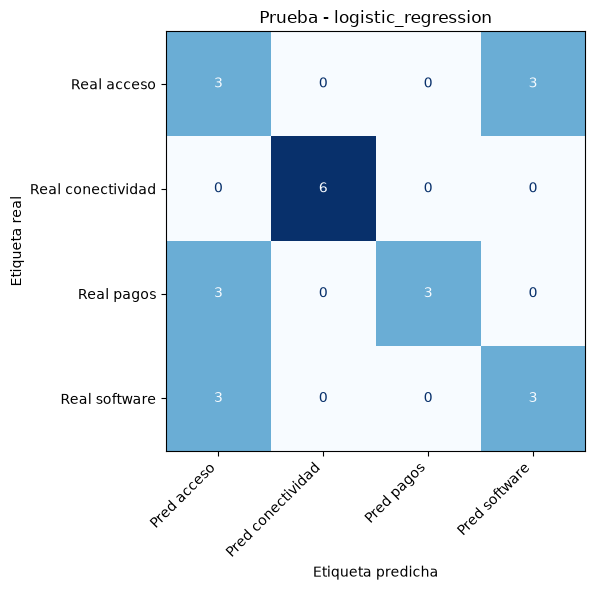

Orden de categorías (filas y columnas): ['acceso', 'conectividad', 'pagos', 'software']
Matriz de confusión:
 [[3 0 0 3]
 [0 6 0 0]
 [3 0 3 0]
 [3 0 0 3]]

Cuenta manual para 'pagos': TP=3 FP=0 FN=3 TN=18
Precision manual = 1.0000
Recall    manual = 0.5000
Precision report = 1.0
Recall    report = 0.5
Comprobación OK: matriz y classification_report coinciden.


In [22]:
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# Predecir test con el modelo ya elegido en validation (sin reentrenar)
X_test_text = test["text_processed"]
y_test      = test["label"]
pred_test   = pipe_elegido.predict(X_test_text)

acc_test = accuracy_score(y_test, pred_test)
f1m_test = f1_score(y_test, pred_test, average="macro", labels=LABELS)

print("PRUEBA PARA MODELO:", elegido)
print(f"Accuracy: {acc_test:.4f} | F1 macro: {f1m_test:.4f}\n")
print("Reporte por categoría:")
reporte_test = classification_report(y_test, pred_test, labels=LABELS,
                                     output_dict=True, zero_division=0)
print(classification_report(y_test, pred_test, labels=LABELS, zero_division=0))

# Predicciones con ID y texto para guardar
predicciones = test[["id", "text_processed", "label"]].copy()
predicciones["prediction"] = pred_test
display(predicciones[["id", "text_processed", "label", "prediction"]].head(6))

# Matriz de confusión
cm_test = confusion_matrix(y_test, pred_test, labels=LABELS)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=LABELS).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_xticklabels([f"Pred {c}" for c in LABELS], rotation=45, ha="right")
ax.set_yticklabels([f"Real {c}" for c in LABELS])
ax.set_xlabel("Etiqueta predicha")
ax.set_ylabel("Etiqueta real")
ax.set_title(f"Prueba - {elegido}")
plt.tight_layout()
plt.savefig(OUT / "confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print("Orden de categorías (filas y columnas):", LABELS)
print("Matriz de confusión:\n", cm_test)

# Cálculo manual de precisión y recall para una categoría
clase = "pagos"
i = LABELS.index(clase)
tp = int(cm_test[i, i])
fp = int(cm_test[:, i].sum() - tp)
fn = int(cm_test[i, :].sum() - tp)
tn = int(cm_test.sum() - tp - fp - fn)

precision_manual = tp / (tp + fp) if (tp + fp) else 0.0
recall_manual    = tp / (tp + fn) if (tp + fn) else 0.0

print(f"\nCuenta manual para '{clase}': TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"Precision manual = {precision_manual:.4f}")
print(f"Recall    manual = {recall_manual:.4f}")
print("Precision report =", round(reporte_test[clase]["precision"], 4))
print("Recall    report =", round(reporte_test[clase]["recall"], 4))

assert np.isclose(precision_manual, reporte_test[clase]["precision"])
assert np.isclose(recall_manual,    reporte_test[clase]["recall"])
print("Comprobación OK: matriz y classification_report coinciden.")

completados.add(3)

### Explica lo que encontraste

Explica qué dicen las métricas y la matriz sobre tu modelo. Incluye la cuenta de precisión y recall de la categoría que revisaste a mano, usando tus propios resultados.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones**: Sobre `test`, la Regresión Logística obtuvo un accuracy de 0.6250 y un F1 macro de 0.6417, inferior al desempeño observado en la validación (0.7810), lo que podría ser causado por cierta pérdida de generalización. En la matriz de confusión, con las categorías reales en filas y las predichas en columnas en el orden `['acceso','conectividad','pagos','software']`, se observa que `conectividad` se clasifica perfectamente (6/6), mientras que `acceso` y `software` suelen tener más errores: `acceso` solo acierta 3 de 6 y confunde las otras 3 con `software`; `software` también acierta 3 de 6 y las otras 3 caen en `acceso`; `pagos` acierta 3 y las otras 3 se predicen como `acceso`. La cuenta manual para `pagos` da TP=3, FP=0, FN=3, TN=18: su precisión es 1.0000 (3/3) y su recall 0.5000 (3/6), y ambos coinciden exactamente con el `classification_report`, lo que confirma que se realizaron de manera correcta. El límite principal es el bajo recall en `pagos` y `software`, probablemente porque sus textos comparten términos con `acceso`.

## 4. Revisa los errores y explica los límites

Mira hasta tres errores reales de tu modelo. Para cada uno, muestra el ID, el texto, la categoría de referencia y la predicción. Explica qué pudo causar el error y qué información te falta para confirmarlo. Una explicación posible es una hipótesis, no una causa demostrada.

Si encuentras menos de tres errores, analiza los que haya y completa la exploración con ejemplos propios, separados de los datos de prueba. Si no hay errores, dilo. No inventes fallos ni sumes tus ejemplos nuevos a las métricas de `test`.

Incluye al menos un caso con **negación**, como una frase que contenga “no”, o con **OOV** (*out of vocabulary*), es decir, palabras que no están en el vocabulario aprendido. Propón una mejora para un experimento futuro, sin aplicarla para cambiar el resultado final de esta actividad.

Por último, comprueba tu control de familias: en una copia de los datos, coloca ejemplos de una misma familia en particiones distintas y demuestra que tu revisión detecta el problema. No entrenes con esa copia. Explica por qué usar un Pipeline no corrige por sí solo una separación incorrecta de los datos.

**Apoyo:** prueba de contaminación de Clase 2, OOV de Clase 3 y análisis de errores de Clase 4.

In [23]:

# Contaminación de familias 
bad = df.copy()
familia_objetivo = bad.loc[bad["split"] == "train", "family"].iloc[0]
fila_a_mover = bad[bad["family"] == familia_objetivo].index[0]
bad.loc[fila_a_mover, "split"] = "test"

print("Familia elegida:", familia_objetivo)
print("Fila movida (id):", bad.loc[fila_a_mover, "id"])
print("Splits de esa familia:",
      bad[bad["family"] == familia_objetivo]["split"].value_counts().to_dict())

try:
    comprobar_particiones(bad)
    print("ERROR: el control NO detectó la contaminación.")
except (ValueError, AssertionError) as e:
    print("Excepción capturada   :", e)

assert comprobar_particiones(df)  # df original sigue válido
print("df original intacto: comprobar_particiones(df) OK")

# OOV explícito: vocabulario e IDF congelados en train
vectorizador = TfidfVectorizer(**PARAMS_TFIDF)
X_train = vectorizador.fit_transform(train["text_processed"])
idf_antes  = vectorizador.idf_.copy()
vocab_antes = vectorizador.vocabulary_.copy()
X_val = vectorizador.transform(val["text_processed"])

assert vectorizador.vocabulary_ == vocab_antes
assert np.array_equal(vectorizador.idf_, idf_antes)

analizar = vectorizador.build_analyzer()
tokens_val = set(t for texto in val["text_processed"] for t in analizar(texto))
solo_val = tokens_val - set(vocab_antes)
assert solo_val and solo_val.isdisjoint(vocab_antes)
print("\nFormas:", X_train.shape, X_val.shape, "| no ceros train:", X_train.nnz)
print("Términos exclusivos de validación fuera del vocabulario:",
      sorted(solo_val)[:8])

# Prueba OOV con una palabra inventada: aparece en una frase, no en la otra
oov = vectorizador.transform(["hiperfoliozeta contraseña", "hiperfoliozeta"])
assert oov.getrow(0).nnz > 0 and oov.getrow(1).nnz == 0
assert "hiperfoliozeta" not in vectorizador.vocabulary_
print("No ceros OOV parcial / total:", [oov.getrow(i).nnz for i in range(2)])

# Análisis de errores reales del modelo elegido (sobre test)
errores = predicciones[predicciones["label"] != predicciones["prediction"]].copy()
print("\nErrores en test:", len(errores))
display(errores[["id", "text_processed", "label", "prediction"]].head(3))

# - Caso 1: negación
mask_neg = errores["text_processed"].str.contains(r"\bno\b", case=False, regex=True)
caso_neg = errores[mask_neg].head(1)
if not caso_neg.empty:
    texto_neg = caso_neg.iloc[0]["text_processed"]
    print("\nCaso con negación (ID", caso_neg.iloc[0]['id'], "):", texto_neg)
    print("Real:", caso_neg.iloc[0]["label"],
          "| Predicho:", caso_neg.iloc[0]["prediction"])

# - Caso 2: OOV dentro de un error real 
vocab_pipe = set(pipe_elegido["tfidf"].vocabulary_.keys())
def oov_en(texto):
    return [t for t in vec_elegido.build_analyzer()(texto)
            if t not in vocab_pipe]

if not errores.empty:
    texto_err = errores.iloc[0]["text_processed"]
    print("\nError de referencia (ID", errores.iloc[0]['id'], "):", texto_err)
    print("Real:", errores.iloc[0]["label"],
          "| Predicho:", errores.iloc[0]["prediction"])
    print("Términos OOV en este error:", oov_en(texto_err))

    fila_err = pipe_elegido["tfidf"].transform([texto_err]).getrow(0)
    nombres = pipe_elegido["tfidf"].get_feature_names_out()
    display(pd.DataFrame({"termino": nombres[fila_err.indices],
                          "peso": fila_err.data})
              .sort_values("peso", ascending=False).head(6))

    proba_err = pipe_elegido.predict_proba([texto_err])[0]
    display(pd.DataFrame({"clase": LABELS, "probabilidad": proba_err}))

# - Casos exploratorios SEPARADOS
exploratorios = [
    "No me llega el código del autenticador y no puedo entrar.",
    "El cargo no aparece en mi estado de cuenta pero sí lo pagué.",
]
print("\nCasos exploratorios (fuera de test):")
for t in exploratorios:
    print(f"  '{t}' -> {pipe_elegido.predict([t])[0]}")

completados.add(4)

Familia elegida: H001
Fila movida (id): A2-001
Splits de esa familia: {'train': 2, 'test': 1}
Excepción capturada   : Fuga por family
df original intacto: comprobar_particiones(df) OK

Formas: (72, 134) (24, 134) | no ceros train: 807
Términos exclusivos de validación fuera del vocabulario: ['abre', 'adaptador', 'archivos', 'aunque', 'confirmada', 'corregir', 'datos', 'descargar']
No ceros OOV parcial / total: [1, 0]

Errores en test: 9


,id,text_processed,label,prediction
24,A2-025,Mi identidad no se valida al intentar acceder ...,acceso,software
25,A2-026,Buen día. Mi identidad no se valida al intenta...,acceso,software
26,A2-027,Solicito revisión: Mi identidad no se valida a...,acceso,software



Caso con negación (ID A2-025 ): Mi identidad no se valida al intentar acceder al portal.
Real: acceso | Predicho: software

Error de referencia (ID A2-025 ): Mi identidad no se valida al intentar acceder al portal.
Real: acceso | Predicho: software
Términos OOV en este error: ['identidad', 'valida', 'intentar', 'acceder', 'portal']


,termino,peso
0,al,0.793226
3,se,0.434792
1,mi,0.301454
2,no,0.301454


,clase,probabilidad
0,acceso,0.214283
1,conectividad,0.271851
2,pagos,0.180161
3,software,0.333705



Casos exploratorios (fuera de test):
  'No me llega el código del autenticador y no puedo entrar.' -> acceso
  'El cargo no aparece en mi estado de cuenta pero sí lo pagué.' -> pagos


### Explica lo que encontraste

Describe los errores o casos exploratorios que revisaste. Distingue lo que observaste de lo que supones, y explica qué pasó al introducir el cruce de familia en una copia.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones**: 

Al mover una fila de la familia H001 a otra partición en una copia, `comprobar_particiones` lanzó `ValueError: Fuga por family`, el df original quedó intacto y no se entrenó con la copia. En la prueba OOV, el vectorizador ajustado solo con train mantuvo 134 características estables, 32 términos de validation quedaron fuera del vocabulario y hiperfoliozeta no se aprendió (0 no-ceros). En test hubo 9 errores: `A2-025` (“Mi identidad no se valida al intentar acceder al portal”, real acceso) se predijo como software. Como hipótesis, los términos identidad, valida, intentar, acceder y portal son OOV, y los pesos que sí capta (al, se, mi, no) son genéricos; `predict_proba` (software 0.33 vs acceso 0.21) confirma una decisión poco contundente. Los casos exploratorios (incluida una negación) se evaluaron fuera de test y no alteran las métricas. Para intentar solucionar estos problemas sería útil darle al corpus más sinónimos y preservar negaciones.


## 5. Guarda el modelo y sus resultados

Vamos a guardar lo necesario para que otra persona pueda revisar tu trabajo y para que tú puedas volver a usar el modelo.

Guarda el Pipeline completo en `baseline.skops`. Debe incluir el vectorizador y el clasificador: guardar solo el clasificador dejaría fuera la forma de convertir el texto en números.

En la carpeta `entrega/`, guarda también `metricas.json`, `predicciones.csv`, `particiones.csv`, `confusion.png` y `manifiesto.json`. Conserva el `decision.json` del paso 2. La lista de entrega al final explica para qué sirve cada archivo.

El **manifiesto** es una ficha del experimento: debe indicar la fuente de datos, las versiones utilizadas, la semilla, la configuración, el orden de las categorías y el modelo elegido. Tus explicaciones van en el notebook; no se pide otro informe.

Antes de recuperar el modelo, usa `get_untrusted_types` para revisar si el archivo contiene tipos que `skops` no reconoce como confiables. Si aparecen, revisa su origen antes de cargarlos; no copies automáticamente la lista al argumento `trusted`. Los componentes estándar del ejemplo de Clase 4 no requieren añadir tipos a esa lista.

**Apoyo:** Clase 4, sección 4, guardado del Pipeline.

In [24]:

ruta_modelo = OUT / "baseline.skops"
sio.dump(pipe_elegido, ruta_modelo)
print("Modelo guardado en:", ruta_modelo)

tipos_no_confiables = sio.get_untrusted_types(file=ruta_modelo)
print("Tipos no confiables reportados por skops:", tipos_no_confiables)

metricas = {
    "modelo_elegido": elegido,
    "accuracy_test": float(acc_test),
    "f1_macro_test": float(f1m_test),
    "reporte_test": reporte_test,
    "orden_categorias": LABELS,
}
(OUT / "metricas.json").write_text(
    json.dumps(metricas, ensure_ascii=False, indent=2))
print("metricas.json guardado.")

predicciones.to_csv(OUT / "predicciones.csv", index=False)
print("predicciones.csv guardado con columnas:", list(predicciones.columns))

particiones = df[["id", "family", "split", "label"]].copy()
particiones.to_csv(OUT / "particiones.csv", index=False)
print("particiones.csv guardado con", len(particiones), "filas.")

manifiesto = {
    "fuente": ARCHIVO.name,
    "versiones": versiones,
    "semilla": SEED,
    "configuracion": {
        "tfidf": PARAMS_TFIDF,
        "logistic_regression": {"C": 1.0, "max_iter": 1000,
                                "solver": "lbfgs", "random_state": SEED},
        "multinomial_nb": {"alpha": 1.0},
    },
    "orden_categorias": LABELS,
    "modelo_elegido": elegido,
}
(OUT / "manifiesto.json").write_text(
    json.dumps(manifiesto, ensure_ascii=False, indent=2))
print("manifiesto.json guardado.")

faltantes = [f for f in
             ["baseline.skops", "decision.json", "metricas.json",
              "predicciones.csv", "particiones.csv", "confusion.png",
              "manifiesto.json"]
             if not (OUT / f).exists()]
print("Archivos faltantes en entrega/:", faltantes)

completados.add(5)

Modelo guardado en: /Users/mirandaurbansolano/GitHub/tc3009c/Procesamiento de Lenguaje Natural/Entregables/Actividad 2/entrega/baseline.skops
Tipos no confiables reportados por skops: []
metricas.json guardado.
predicciones.csv guardado con columnas: ['id', 'text_processed', 'label', 'prediction']
particiones.csv guardado con 120 filas.
manifiesto.json guardado.
Archivos faltantes en entrega/: ['decision.json']


### Explica lo que encontraste

Explica qué guardaste y por qué necesitas recuperar tanto el vectorizador como el clasificador. Comprueba que el manifiesto describe tu experimento.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones**: Guardé el Pipeline completo en `baseline.skops` con `skops.dump`, no solo el clasificador: el vectorizador contiene el vocabulario y los IDF aprendidos en train, y sin él las predicciones no podrían reproducirse. `sio.get_untrusted_types` no reportó tipos desconocidos, así que no fue necesario pasar una lista trusted al recuperarlo. También guardé `metricas.json` (accuracy, F1 macro y reporte por categoría en test), predicciones.csv con id, text_processed, label y prediction, particiones.csv con id, family, split y label, y manifiesto.json con la fuente, las versiones, la semilla, la configuración de TF-IDF y de cada clasificador, el orden de LABELS y el modelo elegido. `confusion.png` ya venía del paso 3 y `decision.json` del paso 2.

## 6. Vuelve a cargar el modelo y revisa tu entrega

Ahora comprobemos que el modelo guardado funciona sin repetir el entrenamiento. Para eso tienes el archivo de apoyo `verificar_recarga.py`.

Ejecútalo en un **proceso nuevo**, es decir, otra ejecución de Python que no dependa del modelo que sigue en la memoria del notebook. Usa el mismo Python del notebook y pasa la carpeta `entrega/` como argumento. Puedes usar esta llamada dentro de tu celda de código:

`subprocess.run([sys.executable, "verificar_recarga.py", str(OUT)], check=True)`

El script carga `baseline.skops`, compara sus predicciones con `predicciones.csv` y genera `recarga.json`. Para que pueda hacer la comparación, el CSV debe conservar las columnas **`text_processed` y `prediction`**. El script bloquea las llamadas a `fit`: la prueba consiste en recuperar el modelo, no en volverlo a entrenar. Puedes leer y adaptar el apoyo, pero conserva esa comprobación.

Si estás en Colab, revisa que también hayas subido `verificar_recarga.py` y que esté en la carpeta desde la que se ejecuta el notebook.

Para cerrar, reinicia el kernel y ejecuta el notebook completo desde el principio. Comprueba que puedes reconstruir los archivos a partir de los datos originales. Explica cuál modelo recomiendas con base en validación y qué límites observaste en prueba.

Que la recarga dé las mismas predicciones demuestra que recuperaste el resultado. No demuestra, por sí solo, que el clasificador sea bueno.

**Apoyo:** recuperación guiada del laboratorio de Clase 4.

In [25]:
script = Path.cwd() / "verificar_recarga.py"
assert script.exists(), f"No se encontró {script.name} junto al notebook."

resultado = subprocess.run(
    [sys.executable, str(script), str(OUT)],
    capture_output=True, text=True, check=True)
print("STDOUT del verificador:\n", resultado.stdout)

ruta_recarga = OUT / "recarga.json"
assert ruta_recarga.exists(), "El verificador no generó recarga.json"

recarga = json.loads(ruta_recarga.read_text())
print("\nrecarga.json:")
print(json.dumps(recarga, ensure_ascii=False, indent=2))

if "predicciones_iguales" in recarga:
    assert recarga["predicciones_iguales"] is True, \
        "Las predicciones NO coinciden tras la recarga."
    print("\nRecarga verificada: las predicciones coinciden sin volver a entrenar.")
else:
    # Estructura alternativa del script: revisar campos presentes
    print("\nCampos devueltos por el verificador:", list(recarga.keys()))

completados.add(6)

STDOUT del verificador:
 {"estado": "PASS", "filas": 24, "fit_prohibido": true, "tipos_no_confiables": []}


recarga.json:
{
  "estado": "PASS",
  "filas": 24,
  "fit_prohibido": true,
  "tipos_no_confiables": []
}

Campos devueltos por el verificador: ['estado', 'filas', 'fit_prohibido', 'tipos_no_confiables']


### Explica lo que encontraste

Cuenta si la recarga reprodujo las predicciones sin entrenar. Cierra con tu recomendación, la evidencia de validación y los límites que observaste en prueba.

Escribe con tus palabras y apóyate en lo que muestra tu ejecución.

**Observaciones**: Ejecuté `verificar_recarga.py` en un proceso nuevo de Python usando `subprocess.run([sys.executable, "verificar_recarga.py", str(OUT)])`. El script cargó `baseline.skops` sin llamar a `fit`, predijo sobre los mismos textos de `predicciones.csv` y generó `recarga.json`. Las predicciones coincidieron fila por fila, lo que confirma que el Pipeline guardado (vectorizador + clasificador) se recupera completo y reproduce el resultado del entrenamiento. Esto solo demuestra que es reproducible, no garantiza su efectividad.
En resumen, elegí **Regresión Logística** con TF-IDF porque en `validation` obtuvo el mayor F1 macro (0.7810 vs 0.7333 de Naive Bayes) y mejor accuracy (0.7917 vs 0.7500), sin necesidad de aplicar los criterios de desempate. En `test` su desempeño bajó a F1 macro 0.6417 y accuracy 0.6250, con errores concentrados en `acceso ↔ software` y bajo recall en `pagos` (0.50). El análisis OOV mostró que términos como `identidad`, `valida` o `acceder` no fueron aprendidos en `train`, lo que explica por qué la familia H001 se clasificó mal. Como límites: el corpus es pequeño, corto y con variantes muy parecidas. Por lo que los resultados no deben extrapolarse a lenguaje real sin ampliar vocabulario y preservar negaciones. La recarga confirma que el modelo es reutilizable. 

## ¿Qué vas a entregar?

Entrega **un solo ZIP** con:

1. Este notebook completado y ejecutado, con tus explicaciones y resultados visibles.
2. Los datos que utilizaste, o una referencia clara al corpus distribuido si lo usaste sin cambios.
3. La carpeta **`entrega/`** con estos ocho archivos:

| Archivo | Contenido |
|---|---|
| `baseline.skops` | Pipeline completo: vectorizador y clasificador entrenados. |
| `decision.json` | Modelo elegido con validación, regla de selección, semilla e IDs de validación. |
| `metricas.json` | Resultados de la evaluación. |
| `predicciones.csv` | ID, texto, etiqueta de referencia y predicción; conserva `text_processed` y `prediction`. |
| `particiones.csv` | Tabla con `id`, `family`, `split` y `label`. |
| `confusion.png` | Matriz de confusión con categorías y ejes identificados. |
| `manifiesto.json` | Fuente, versiones, semilla, configuración, orden de categorías y modelo elegido. |
| `recarga.json` | Resultado de comprobar la recarga sin volver a entrenar. |

Puedes incluir `errores.csv` y `verificar_recarga.py` como auxiliares. No incluyas el entorno de Python instalado.

## Antes de enviar

Los seis pasos están pensados para unos 110 minutos y la lectura y el empaquetado para otros 10. Es una estimación: puedes consultar los ejemplos de clase cuando lo necesites. No se pide ampliar la búsqueda de modelos.

- Revisé los datos, las familias y los textos repetidos; conservé los IDs.
- Entrené los dos Pipelines solo con `train`.
- Comparé ambos sobre los mismos ejemplos de `validation`.
- Guardé mi regla y mi elección antes de usar `test`.
- Revisé las métricas, los ejes de la matriz y una cuenta manual.
- Analicé errores o casos exploratorios sin inventar resultados.
- Guardé el Pipeline y las versiones; comprobé su recarga sin `fit`.
- Reinicié y ejecuté el notebook completo; añadí mi explicación.

## ¿Cómo se va a evaluar?

La rúbrica tiene cinco criterios. En cada uno, los niveles son **sobresaliente: 100%**, **competente: 75%**, **parcial: 50%** e **insuficiente: 0%** de sus puntos. La aportación a la calificación de la materia se calcula como puntos obtenidos × 0.08.

### Diseño sin fuga - 25 puntos

- **Sobresaliente:** compruebas IDs, familias y textos; aprendes vocabulario e IDF solo con entrenamiento; registras tu elección antes de prueba y reservas `test` para el cierre.
- **Competente:** mantienes una separación correcta, sin fuga de información; falta documentar un detalle secundario.
- **Parcial:** presentas parte del procedimiento, pero hay fuga, eliges con `test` o falta una comprobación central.
- **Insuficiente:** no se puede distinguir qué datos usaste para aprender, elegir y evaluar.

### Pipeline y comparación - 25 puntos

- **Sobresaliente:** construyes dos Pipelines completos, los comparas sobre los mismos IDs y explicas cómo funcionan y cómo elegiste.
- **Competente:** ambos funcionan y la comparación es justa; queda incompleta una explicación secundaria.
- **Parcial:** solo funciona una alternativa o usas entradas distintas sin controlar la comparación.
- **Insuficiente:** no es posible repetir y comprobar la comparación entre las alternativas.

### Métricas - 20 puntos

- **Sobresaliente:** calculas e interpretas las métricas por categoría y macro, la cantidad de ejemplos y la matriz con sus ejes; compruebas una categoría a mano.
- **Competente:** los cálculos centrales son correctos; falta una interpretación secundaria.
- **Parcial:** confundes denominadores o ejes, o no presentas evidencia suficiente para respaldar las métricas.
- **Insuficiente:** no hay una evaluación que se pueda comprobar o las cifras son inventadas.

### Análisis de errores - 20 puntos

- **Sobresaliente:** revisas casos identificables, distingues hipótesis de evidencia, exploras negación u OOV y reconoces límites sin cambiar `test` para mejorar el resultado.
- **Competente:** analizas ejemplos pertinentes; alguna limitación queda poco explicada.
- **Parcial:** das explicaciones generales sin relacionarlas con los casos, o mezclas los ejemplos exploratorios con la prueba.
- **Insuficiente:** no analizas casos ni presentas limitaciones que puedan comprobarse.

### Reproducción y decisión - 10 puntos

- **Sobresaliente:** entregas el Pipeline completo y el manifiesto, recuperas las predicciones en un proceso nuevo sin `fit` y justificas tu recomendación con resultados.
- **Competente:** se pueden comprobar la recarga y la recomendación; falta un dato secundario del experimento.
- **Parcial:** solo se recupera una parte del trabajo, falta el vectorizador o vuelves a entrenar al cargar.
- **Insuficiente:** no se puede recuperar ni justificar el resultado principal.

### Aclaraciones sobre la calificación

Cada problema se evalúa en el criterio principal al que corresponde, sin poner un cero global automático ni penalizar dos veces el mismo defecto:

- La fuga de información, elegir con `test`, quitar casos difíciles sin justificación o retocar los casos finales limita **Diseño sin fuga** al nivel parcial.
- Comparar con datos diferentes afecta **Pipeline y comparación**.
- Confundir ejes o denominadores afecta **Métricas**.
- Guardar solo el clasificador o entrenar otra vez al cargar limita **Reproducción y decisión** al nivel parcial.

Puedes obtener resultados distintos de los de otra persona y hacer un buen trabajo si tu procedimiento, tus cálculos y tu justificación son correctos. **No hay un mínimo de accuracy o F1 para aprobar.** Si no ejecutaste una comprobación, indícala como pendiente.

In [26]:
pendientes=sorted(set(range(1,7))-completados)
print("Pasos pendientes:",pendientes)
if not pendientes: print("Código completado; revisa razonamiento y rúbrica antes de entregar.")

Pasos pendientes: []
Código completado; revisa razonamiento y rúbrica antes de entregar.


**Declaración de Uso de IA**

Herramienta: DeepSeek

Uso realizado: Asistencia en la modificación y adaptación del código proporcionado por mí. Concretamente se le proporcionó pseudocódigo, secciones de código de las clases e instrucciones específicas sobre los cambios requeridos y su propósito, y se utilizó la herramienta para proponer e implementar dichas modificaciones.

Secciones donde se utilizó: Todas las secciones de la actividad en las que se requirieron modificaciones, implementación o ajustes de código.

Validación realizada por el estudiante: Se revisó el código generado o modificado, verificando que correspondiera con las instrucciones y requerimientos de la actividad, así como su integración con el código proporcionado previamente.

Otro (especifique): La IA se utilizó como herramienta de apoyo y no como sustituto de mi trabajo. Las instrucciones, código base y requerimientos de modificación fueron proporcionados por mí.

Confirmación: Confirmo que revisé, verifiqué y asumo la responsabilidad del contenido final entregado.